# Experiment 4 — Hypothesis Testing (Titanic Dataset)

**Covers:** Welch's t-test, z-test, Chi-square test, ANOVA, Tukey HSD, plots, p-value decisions, summary and CSV export.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** ttest_ind → ztest → crosstab + chi2_contingency → f_oneway → pairwise_tukeyhsd.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

df = pd.read_csv("train.csv")

## Decision rule
If p < 0.05 → reject H0, otherwise fail to reject H0.

- **T / Z-test** H0: males and females paid the same mean fare
- **Chi-square** H0: survival is independent of sex
- **ANOVA** H0: mean fare is the same in all three classes

In [2]:
def decide(p):
    return "Reject H0" if p < 0.05 else "Fail to reject H0"

## 1. T-test: `Fare` by `Sex` (male vs female)

male: 577 25.524 43.138
female: 314 44.48 57.998


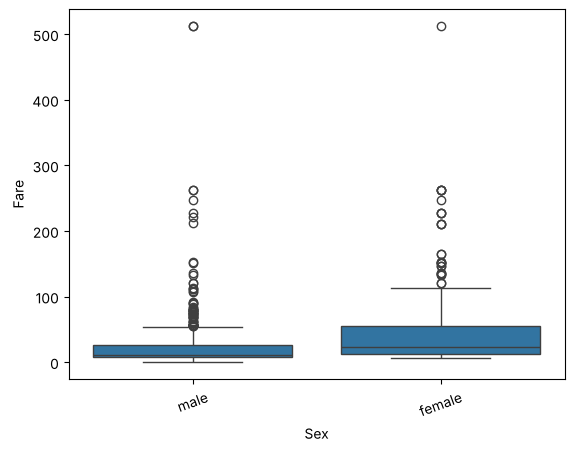

T-test: -5.077499013458909 5.388057409693924e-07 Reject H0


In [3]:
g1 = df[df["Sex"] == "male"]["Fare"].dropna()
g2 = df[df["Sex"] == "female"]["Fare"].dropna()

print("male:", len(g1), round(g1.mean(), 3), round(g1.std(), 3))
print("female:", len(g2), round(g2.mean(), 3), round(g2.std(), 3))

sns.boxplot(data=df, x="Sex", y="Fare")
plt.xticks(rotation=20)
plt.show()

t, p1 = ttest_ind(g1, g2, equal_var=False)
print("T-test:", t, p1, decide(p1))

## 2. Z-test: same two groups (large-sample test of means)

In [4]:
z, p2 = ztest(g1, g2)
print("Z-test:", z, p2, decide(p2))

Z-test: -5.529140269385719 3.218039631136631e-08 Reject H0


## 3. Chi-square: `Sex` vs `Survived`

Survived    0    1
Sex               
female     81  233
male      468  109


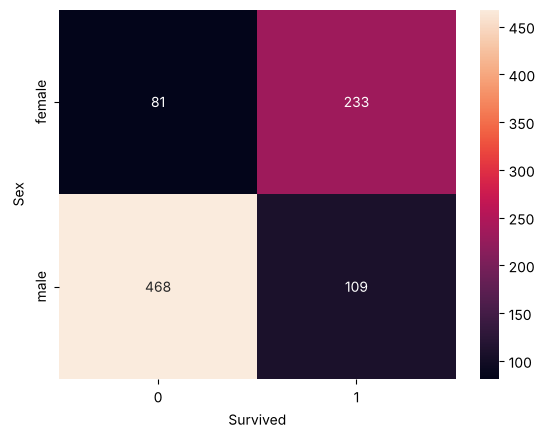

Chi-square: 260.71702016732104 DOF: 1 p: 1.1973570627755645e-58 Reject H0
Expected frequencies: [[193.5 120.5]
 [355.5 221.5]]
Expected cells >= 5: 100.0 %


In [5]:
table = pd.crosstab(df["Sex"], df["Survived"])
print(table)

sns.heatmap(table, annot=True, fmt="d")
plt.show()

chi, p3, dof, expected = chi2_contingency(table)
print("Chi-square:", chi, "DOF:", dof, "p:", p3, decide(p3))
print("Expected frequencies:", expected.round(1))
print("Expected cells >= 5:", (expected >= 5).mean() * 100, "%")

## 4. ANOVA: `Fare` by `Pclass`

        count       mean
Pclass                  
1         216  84.154687
2         184  20.662183
3         491  13.675550


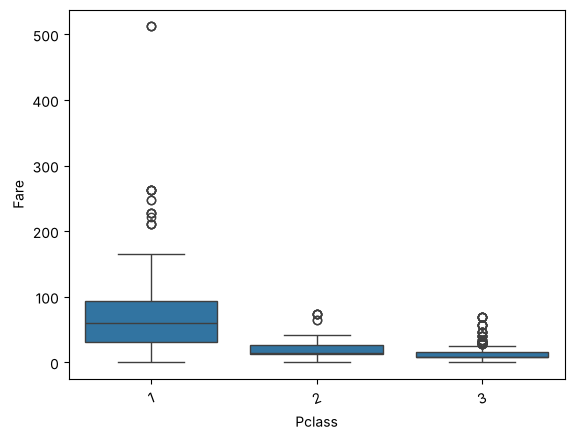

ANOVA: 242.34415651744814 1.031376320913912e-84 Reject H0


In [6]:
groups = [g["Fare"].dropna() for _, g in df.groupby("Pclass")]

print(df.groupby("Pclass")["Fare"].agg(["count", "mean"]))
sns.boxplot(data=df, x="Pclass", y="Fare")
plt.xticks(rotation=20)
plt.show()

f, p4 = f_oneway(*groups)
print("ANOVA:", f, p4, decide(p4))

## 5. Tukey HSD (which pairs differ?)

In [7]:
print(pairwise_tukeyhsd(df["Fare"], df["Pclass"]))

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
     1      2 -63.4925   0.0 -72.9165 -54.0685   True
     1      3 -70.4791   0.0 -78.1489 -62.8094   True
     2      3  -6.9866 0.108 -15.1064   1.1331  False
-----------------------------------------------------


## 6. Summary and save

In [8]:
result = pd.DataFrame({
    "Test": ["T-test", "Z-test", "Chi-square", "ANOVA"],
    "Statistic": [t, z, chi, f],
    "P-value": [p1, p2, p3, p4],
    "Decision": [decide(p) for p in [p1, p2, p3, p4]]
})
print(result)

result.to_csv("hypothesis.csv", index=False)
print("Saved hypothesis.csv")

         Test   Statistic       P-value   Decision
0      T-test   -5.077499  5.388057e-07  Reject H0
1      Z-test   -5.529140  3.218040e-08  Reject H0
2  Chi-square  260.717020  1.197357e-58  Reject H0
3       ANOVA  242.344157  1.031376e-84  Reject H0
Saved hypothesis.csv


## Result / Conclusion
- **T-test / Z-test:** females paid a higher mean fare than males (44.48 vs 25.52, t = −5.08, p ≈ 5e-7) → reject H0.
- **Chi-square:** survival depends on sex (χ² = 260.7, p ≈ 1e-58).
- **ANOVA:** mean fare differs between classes (F = 242.3, p ≈ 1e-84).
- **Tukey HSD:** 1st class differs from 2nd and 3rd, but 2nd vs 3rd is **not** significant (p = 0.108).